In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import logging
import random
from copy import deepcopy
import re
from sklearn.metrics import mean_squared_error

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import torch
import numpy as np
from dotenv import load_dotenv
from natsort import natsorted

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

In [2]:
runs_to_download = []

runs_to_download.extend(mlflow.search_runs(filter_string="params.model_class = 'HybridModel'",
      experiment_ids=['11'], output_format='list'))
runs_to_download.extend(mlflow.search_runs(
      filter_string=f"attributes.status = 'FINISHED' and params.model_class = 'MLP' and tags.mlflow.parentRunId ='f02bf732b2ba4817b254bd5174f1549b'",
            experiment_ids=['6'], output_format='list'))
print(len(runs_to_download))

16


In [3]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-09-22 16:17:26,538 - INFO - Downloading artifacts for run 92451521018f489bac71460af3236796
2026-09-22 16:17:33,986 - INFO - Downloading artifacts for run 3794011a45bf4f9f934ab14c89bc1bcd
2026-09-22 16:17:36,582 - INFO - Downloading artifacts for run 54d849118e484360adecaba03b6fd3e6
2026-09-22 16:17:40,627 - INFO - Downloading artifacts for run b8757314360d456ba3cf0c3b593a944d
2026-09-22 16:17:43,464 - INFO - Downloading artifacts for run 96b0514deccc4e90a1668e0fed535dd9
2026-09-22 16:17:44,249 - WARNING - No 'evaluation' artifacts for run 96b0514deccc4e90a1668e0fed535dd9 (parent run f02bf732b2ba4817b254bd5174f1549b). Skipping.
2026-09-22 16:17:44,251 - INFO - Downloading artifacts for run af8e292e3c224c4ea52fdd72a7b43874
2026-09-22 16:17:46,628 - INFO - Downloading artifacts for run e133986c051241998f099e8940ce2bc9
2026-09-22 16:17:49,098 - INFO - Downloading artifacts for run 69392c381d204a93abceae263db2fb1f
2026-09-22 16:17:51,677 - INFO - Downloading artifacts for run e043ef573

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.069758,0.069758,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.510657,0.510657,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.268661,0.268661,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.671873,0.671873,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.000000,0.000000,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b


In [4]:
raw_predictions_df.shape

(1470000, 7)

In [5]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None),
        'parameters_set_to_zero': run.data.params.get('parameters_set_to_zero', None) })
model_name_df = pd.DataFrame(model_name_records)
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes,parameters_set_to_zero
0,Node_0,0.0,0.069758,0.069758,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']"
1,Node_1,0.0,0.510657,0.510657,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']"
2,Node_2,0.0,0.268661,0.268661,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']"
3,Node_3,0.0,0.671873,0.671873,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']"
4,Node_4,0.0,0.000000,0.000000,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']"


In [6]:
raw_predictions_df.model_name.value_counts()

model_name
HybridModel    1365000
MLP             105000
Name: count, dtype: int64

In [7]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-09-22 16:25:25,281 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-22 16:25:25,386 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-22 16:25:25,479 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-22 16:25:25,607 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-22 16:25:25,700 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-22 16:25:25,789 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-22 16:25:25,921 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-22 16:25:26,016 - WARNING - Connection p

In [8]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    run = mlflow.get_run(run_id)
    records.append({
        'parent_run_id': run_id,
        'nr_genes': run.data.params['nr_genes'],
    })
nr_genes_df = pd.DataFrame(records)
nr_genes_df.head()

,parent_run_id,nr_genes
0,f02bf732b2ba4817b254bd5174f1549b,50


In [9]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

outcome.head()

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,modelled_genes,parameters_set_to_zero,ground_truth_from_simulation,run_id_from_simulation,nr_genes
0,Node_0,0.0,0.069758,0.069758,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']",0.022225,f02bf732b2ba4817b254bd5174f1549b,50
1,Node_1,0.0,0.510657,0.510657,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']",0.557310,f02bf732b2ba4817b254bd5174f1549b,50
2,Node_2,0.0,0.268661,0.268661,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']",0.080057,f02bf732b2ba4817b254bd5174f1549b,50
3,Node_3,0.0,0.671873,0.671873,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']",0.702816,f02bf732b2ba4817b254bd5174f1549b,50
4,Node_4,0.0,0.000000,0.000000,KO: Node_32. Env: None,92451521018f489bac71460af3236796,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...","['a_0_Node_18', 'a_0_Node_9']",0.057769,f02bf732b2ba4817b254bd5174f1549b,50


In [10]:
outcome.model_name.value_counts()

model_name
HybridModel    1365000
MLP             105000
Name: count, dtype: int64

In [11]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'nr_genes', 'parameters_set_to_zero']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

In [12]:
outcome['parameters_set_to_zero'].value_counts()

parameters_set_to_zero
['a_0_Node_18', 'a_0_Node_9']                                                                                                                          105000
['a_0_Node_41', 'a_0_Node_9']                                                                                                                          105000
['a_0_Node_36', 'a_1_Node_9']                                                                                                                          105000
['a_1_Node_10', 'a_1_Node_33']                                                                                                                         105000
['a_0_Node_32', 'a_3_Node_32']                                                                                                                         105000
['a_7_Node_0', 'a_3_Node_28', 'a_1_Node_13', 'a_0_Node_4']                                                                                             105000
['a_1_Node_0', 'a_2_Node_13',

In [13]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [14]:
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
        lambda row: lookup[(
            row['condition'],
            row['modelled_genes'] if row['modelled_genes'] is not None else None
        )],
    axis=1
)
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [15]:
double_ko_df.model_name.value_counts()

model_name
HybridModel    682500
MLP             52500
Name: count, dtype: int64

In [16]:
groupby_list = [
    'model_name',
    'modelled_genes',
    'nr_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'parameters_set_to_zero'
]
mse_df = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

mlp_mse = mse_df[mse_df['model_name'] == 'MLP'][['gene', 'condition', 'MSE', 'nr_genes']].rename(columns={'MSE': 'mlp_mse'})
hybrid_mse = mse_df[mse_df['model_name'] == 'HybridModel'][['gene', 'condition', 'MSE', 'modelled_genes', 'nr_genes']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mlp_mse, on=['gene', 'condition', 'nr_genes'])
paired = annotate_kos_in_df(paired)
paired

,gene,condition,hybrid_mse,modelled_genes,nr_genes,mlp_mse,ko_in_mm,gene_in_mm
0,Node_0,"KO: Node_0, Node_13. Env: None",0.033959,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.033210,none,False
1,Node_0,"KO: Node_0, Node_13. Env: None",0.036246,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.033210,none,False
2,Node_0,"KO: Node_0, Node_13. Env: None",0.034091,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.033210,none,False
3,Node_0,"KO: Node_0, Node_19. Env: None",0.051863,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.050229,none,False
4,Node_0,"KO: Node_0, Node_19. Env: None",0.057033,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.050229,none,False
...,...,...,...,...,...,...,...,...
32495,Node_9,"KO: Node_8, Node_16. Env: None",0.002321,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",50,0.002025,none,True
32496,Node_9,"KO: Node_8, Node_16. Env: None",0.002413,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",50,0.002025,none,True
32497,Node_9,"KO: Node_8, Node_31. Env: None",0.003032,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",50,0.006859,none,True
32498,Node_9,"KO: Node_8, Node_31. Env: None",0.003052,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",50,0.006859,none,True


In [ ]:
from functools import lru_cache

@lru_cache(maxsize=None)
def cached_check(gene_name, ko_string):
    return sim_output.network.get_ko_to_target_distance(gene_name, ko_string)

paired["KO-to-target distance"] = paired.apply(
    lambda row: cached_check(row["gene"], row["condition"]),
    axis=1)
paired['KO-to-target distance'].describe()

In [ ]:
# 1. Get the sorted, unique integers from your dataframe
unique_ints = sorted(paired['KO-to-target distance'].unique())

# 2. Generate a continuous palette with exactly that many colors
# "viridis", "Blues", "magma", etc., will all work here
gradient_colors = sns.color_palette("magma", n_colors=len(unique_ints))

# 3. Zip them into a dictionary: {1: color1, 2: color2, ...}
custom_palette = dict(zip(unique_ints, gradient_colors))

In [17]:
epistasis_df = pd.read_csv('epistasis_levels.csv')

In [ ]:
paired.head()

In [ ]:
epistasis_df.head()

In [18]:
paired = pd.merge(paired, epistasis_df[['condition', 'gene', 'single-to-double-ko-divergence']])

In [22]:
paired.head()

,gene,condition,hybrid_mse,modelled_genes,nr_genes,mlp_mse,ko_in_mm,gene_in_mm,single-to-double-ko-divergence
0,Node_0,"KO: Node_0, Node_13. Env: None",0.033959,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.03321,none,False,0.167792
1,Node_0,"KO: Node_0, Node_13. Env: None",0.033959,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.03321,none,False,0.019585
2,Node_0,"KO: Node_0, Node_13. Env: None",0.036246,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.03321,none,False,0.167792
3,Node_0,"KO: Node_0, Node_13. Env: None",0.036246,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.03321,none,False,0.019585
4,Node_0,"KO: Node_0, Node_13. Env: None",0.034091,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",50,0.03321,none,False,0.167792


In [23]:
def get_col_label(row):
    if row['gene_in_mm']:
        return f"gene in MM,KO in mm = {row['ko_in_mm']}"
    else:
        return 'gene not in MM'
paired['col_label'] = paired.apply(get_col_label, axis=1)

In [ ]:
paired.sort_values(by='hybrid_mse', ascending=False).head()

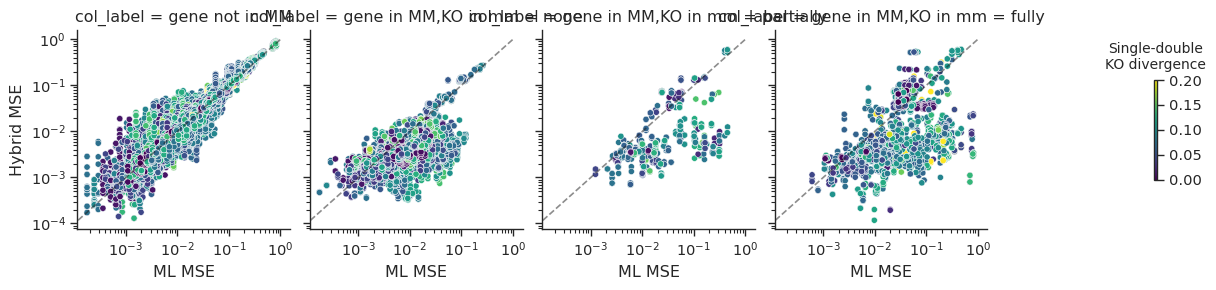

In [28]:
from matplotlib.colors import LogNorm, Normalize
import textwrap 

sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')

min_scale = round(paired['single-to-double-ko-divergence'].quantile(0.01), 1)
max_scale = round(paired['single-to-double-ko-divergence'].quantile(0.99), 1)

palette = sns.color_palette()
cmap = 'viridis'

norm = Normalize(min_scale, max_scale)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='col_label',
                hue='single-to-double-ko-divergence', palette=cmap, hue_norm=norm, legend=False,
                s=20, height=3, aspect=1, facet_kws={'margin_titles': True}) 
# g.figure.set_size_inches(6, 3) 
g.set(xscale="log", yscale="log")
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
g.set_axis_labels('ML MSE', 'Hybrid MSE')
cbar = g.figure.colorbar(sm, 
                        ax=g.axes, 
                        shrink=0.5,       # scales the bar's length (0 to 1)
                        aspect=30,        # higher = thinner bar (default is ~20)
                        fraction=0.03,    # how much of the figure width it eats up
                        pad=0.15,         # gap between the bar and the last facet
                        )

wrapped_title = textwrap.fill('Single-double KO divergence', width=15)

cbar.ax.set_title(wrapped_title, fontsize=10, pad=8)
cbar.set_ticks(np.arange(min_scale, max_scale+0.05, 0.05))
# plt.tight_layout()
# for text in g._margin_titles_texts:
#     text.set_visible(False)

g.savefig("mlp_vs_hybrid_with_mistakes_log_hue_divergence.pdf", dpi=600, bbox_inches='tight')

In [ ]:
stdev_df = outcome.groupby(['gene', 'condition', 'nr_genes'])['noiseless_ground_truth'].std().reset_index().rename(
    columns={'noiseless_ground_truth': 'gene_expression_stdev'})
stdev_df.head()

In [ ]:
paired = pd.merge(paired, stdev_df, 'left', on=['gene', 'condition', 'nr_genes'])

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', row='gene_in_mm', col='ko_in_mm', hue='KO-to-target distance', palette=custom_palette,
                #   legend=False, 
                  alpha=.75, s=20, height=3, aspect=1, facet_kws={'margin_titles': True})
# g.figure.set_size_inches(6, 3) 
# g.set(xscale="log", yscale="log")
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
# plt.tight_layout()
# for text in g._margin_titles_texts:
#     text.set_visible(False)

g.savefig("mlp_vs_hybrid_with_mistakes_lin.pdf", dpi=600, bbox_inches='tight')

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', row='gene_in_mm', col='ko_in_mm', hue='gene_expression_stdev', palette='magma',
                #   legend=False, 
                  alpha=.75, s=20, height=3, aspect=1, facet_kws={'margin_titles': True})
# g.figure.set_size_inches(6, 3) 
# g.set(xscale="log", yscale="log")
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
# plt.tight_layout()
# for text in g._margin_titles_texts:
#     text.set_visible(False)

g.savefig("mlp_vs_hybrid_with_mistakes_lin_hue_stdev.pdf", dpi=600, bbox_inches='tight')